# Make a plan

For any `account_id`, this gives a goal plan (build an emergency fund) and a backup plan for the chosen shock, both from that customer's own numbers. Every shock size has a default and takes a typed value.

## Main findings

**Cuts inside the customer's own spending can get most accounts through a 6-month EI layoff, though the EI maximum makes those cuts much larger.**

| 6 months on EI, all 4,500 accounts | Flat 55% (judges) | With the $729 maximum |
| :-- | --: | --: |
| Last with no changes | 2,904 | 2,191 |
| Last with the customer's own cuts | 1,526 | 2,102 |
| Cuts aren't enough | 47 | 184 |
| No buffer | 23 | 23 |
| Typical cut, % of spending | 15.7% | 38.5% |
| Accounts needing to cut over half of spending | 17 | 600 |

**A surplus on paper often doesn't reach the balance.** On the 1,106 accounts with a surplus still to save, the typical surplus is $824 a month but the balance actually changed by $237. On 444 of them (40%) the balance didn't grow at all over the last 12 months, so the plan shows both figures and treats the savings figure as the most this could be.

| Goal plan | 3-month target | 6-month target |
| :-- | --: | --: |
| Already there | 2,449 | 1,222 |
| Has a surplus to save | 1,106 | 2,154 |
| No surplus, so a cut comes first | 868 | 1,047 |
| No regular spending, so no target | 77 | 77 |

## Limits

- A plan shows what the numbers require. It isn't a forecast or financial advice.
- Flexible spending means anything not visibly fixed. Much of it is cash withdrawals, which could include rent or other bills the data can't label, so a cut that fits on paper may not be possible.
- The EI maximum treats typical money in as insurable earnings. Tax and EI eligibility aren't modelled.
- Income is $0 after the lower income ends, which is the cautious reading.

## Definitions

The numbers come from the engine in `app/engine/`, described in [`docs/engine_contract.md`](docs/engine_contract.md). Shock sizes are explained in [`docs/shock_sizing.md`](docs/shock_sizing.md).

### Goal plan: build an emergency fund

The goal plan assumes no shock.

| Number | Definition |
| :-- | :-- |
| Target | Target months × S |
| Still needed | Target − B |
| Monthly surplus | I − S |
| Monthly saving | Surplus × share saved (all of it by default) |
| Months to goal | Still needed ÷ monthly saving, rounded up |
| Actual change | Mean of money in − money out over the last 12 rows. It shows whether the surplus really stays in the account |

| Goal state | Meaning |
| :-- | :-- |
| `already_there` | B already meets the target |
| `on_track` | There's a surplus to save |
| `no_surplus` | S is at least I, so the plan gives the cut needed |
| `no_regular_spending` | S is $0, so a target in months of spending has no meaning |

### Backup plan: if the shock hits

| Number | Definition |
| :-- | :-- |
| Fixed costs | Current fixed costs, plus any bills added by the shock |
| Flexible spending | S minus current fixed costs, at least $0 |
| Cut to last the period | Gap minus buffer left ÷ months in the period |
| Steps | In order: cover a negative buffer, cancel unlabelled standing orders, bring spending down to the account's own leanest quarter of months, cut all flexible spending, ask the lender |

| Backup state | Meaning |
| :-- | :-- |
| `no_cuts_needed` | The money lasts the period as it is |
| `cuts_needed` | Cuts within flexible spending make it last |
| `cuts_not_enough` | Even cutting all flexible spending doesn't make it last |
| `no_buffer` | The buffer is already zero or negative |
| `no_shock` | No shock was requested |

**Assumption:** income is $0 after the lower income ends. EI ending doesn't mean a new job has started, so this is the cautious reading.

## Setup

In [1]:
import math
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd()
if not (ROOT / "app" / "engine").exists():
    raise RuntimeError("Run this notebook from the Tangerine folder.")
sys.path.insert(0, str(ROOT))

from app.engine import (EI_WEEKLY_MAX_2026, EngineError, IncomeCut, Shock, apply_shock, get_profile, make_plan, warm_up)

warm_up()
pd.set_option("display.max_columns", 30, "display.width", 160)
pd.options.display.float_format = "{:,.1f}".format

MANY_MONTHS = 120             # Beyond this, "months to goal" isn't a useful number to show.

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"   # Passed the dataviz palette validator as a pair.
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 130,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 9.5, "text.color": INK2, "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.titlesize": 11, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "grid.color": GRID, "grid.linewidth": 0.7, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "lines.linewidth": 2,
})

def money(v):
    return "n/a" if v is None else (f"-${abs(v):,.0f}" if v < 0 else f"${v:,.0f}")

def table(headers, rows, align=None):
    align = align or [":--"] + ["--:"] * (len(headers) - 1)
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(align) + " |"]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    return "\n".join(lines)

print("Engine ready.")

Engine ready.


## The calculation

`build_plan` turns the inputs into a shock and asks the engine for the plan. With the EI maximum on, the engine adds a second runway and a second backup plan on the capped income. The judges' flat runway doesn't change and stays beside them.

In [2]:
def build_shock(keep=0.55, months=6, bills_pct=0, repair_dollars=0, repair_months=0, start_month=None, weekly_max=None):
    cut = IncomeCut(keep_fraction=keep, months=months, ei_weekly_max=weekly_max) if keep < 1 else None
    return Shock(income_cut=cut, bills_increase_pct=bills_pct, one_off_dollars=repair_dollars,
                 one_off_spending_multiple=repair_months, start_month=start_month)


def build_plan(account_id, *, target_months=3, keep=0.55, months=6, bills_pct=0, repair_dollars=0, repair_months=0,
               start_month=None, use_ei_max=False, ei_weekly_max=EI_WEEKLY_MAX_2026):
    shock = build_shock(keep, months, bills_pct, repair_dollars, repair_months, start_month, ei_weekly_max if use_ei_max else None)
    judges = apply_shock(account_id, shock, through_months=months)
    plan = make_plan(account_id, shock, target_months=target_months, through_months=months)
    capped = judges.ei_capped if plan.backup_capped is not None else None
    return dict(plan=plan, backup=plan.backup_capped or plan.backup, shock=shock, months=months, judges=judges,
                capped=capped, result=capped or judges, profile=get_profile(account_id))


def path_after_steps(bundle):
    """Balances by month if the customer makes every monthly saving in the backup plan."""
    saving = sum(s.monthly_saving for s in bundle["backup"].steps)
    if saving <= 0:
        return None
    shock = replace(bundle["shock"], other_spending_change=bundle["shock"].other_spending_change - saving)
    result = apply_shock(bundle["plan"].account_id, shock, through_months=bundle["months"])
    source = result.ei_capped if bundle["capped"] is not None else result
    return None if source.duration is None else source.duration.balance_by_month

## The display

`show_plan` shows the goal plan, then the backup plan, then two charts.

In [3]:
GOAL_TEXT = {
    "already_there": lambda g: f"The buffer of {money(g.current_buffer)} already covers {g.target_months:g} months of spending ({money(g.target_amount)}), so no extra saving is needed.",
    "no_surplus": lambda g: f"Typical spending is at or above typical money in, so nothing is left to save. Cutting {money(g.cut_to_break_even)} a month breaks even, and cutting {money(g.cut_to_reach_in_horizon)} a month reaches {money(g.target_amount)} in 12 months.",
    "no_regular_spending": lambda g: "Typical spending is $0, so a target in months of spending has no meaning for this account.",
}

def months_text(n):
    if n is None:
        return "n/a"
    return f"over {MANY_MONTHS} months" if n > MANY_MONTHS else f"{n:,} months"

def goal_text(g):
    if g.state == "on_track":
        return (f"Saving the {money(g.monthly_amount)} monthly surplus takes the buffer from {money(g.current_buffer)} "
                f"to {money(g.target_amount)} ({g.target_months:g} months of spending) in **{months_text(g.months_to_goal)}**.")
    return GOAL_TEXT[g.state](g)

def backup_text(b, result):
    d = result.duration
    if b.state == "no_shock":
        return "No shock was requested, so there's no backup plan to show."
    if b.state == "no_buffer":
        return f"The buffer is already gone, so {money(b.cover_needed)} is needed to get back to $0 before anything else. Cuts can then stop it falling further."
    length = f"{d.months_asked} months"
    if b.state == "no_cuts_needed":
        return f"The money lasts {length} with no changes."
    if b.state == "cuts_needed":
        return f"Without changes, the money runs out in month {d.runs_out_in_month} of {d.months_asked}. Cutting **{money(b.cut_to_last)} a month** ({b.cut_to_last_share_of_spending:.0%} of spending) makes it last."
    return f"Without changes, the money runs out in month {d.runs_out_in_month} of {d.months_asked}. Even cutting all {money(b.flexible_spending)} of flexible spending doesn't make it last, so this customer also needs other help." + (" Asking the lender is the last step below." if any(s.needs_agreement for s in b.steps) else "")


def plan_report(bundle):
    p, plan, judges, capped = bundle["profile"], bundle["plan"], bundle["judges"], bundle["capped"]
    g, b, low = plan.goal, bundle["backup"], plan.low_balance
    out = [f"## Plan for account {plan.account_id}"]

    out.append("### Goal plan: emergency fund\n\n" + goal_text(g))
    if g.state != "no_regular_spending":
        out.append(table(["Measure", "Value"], [
            ["Target", f"{money(g.target_amount)} ({g.target_months:g} months of spending)"],
            ["Buffer now", f"{money(g.current_buffer)} ({g.months_covered:.1f} months)" if g.months_covered is not None and g.current_buffer > 0 else money(g.current_buffer)],
            ["Still needed", money(g.still_needed)],
            ["Typical monthly surplus (I − S)", money(g.surplus)],
            ["Actual change, last 12 months (average a month)", money(g.actual_change_last_12)],
            ["Months to goal", months_text(g.months_to_goal) if g.state == "on_track" else ("Reached" if g.state == "already_there" else "n/a")],
        ]))
    notes = [f.message for f in plan.facts]
    if notes:
        out.append("\n".join(f"- {n}" for n in notes))
    if low is not None:
        line = f"**Keep the lowest balance above one loan payment ({money(low.payment)}).** Its lowest point in the last 6 months was {money(low.lowest_balance)}"
        line += ", so this is met." if low.met else f", so it needs {money(low.top_up_needed)} more."
        out.append(line)

    out.append("### Backup plan: if the shock hits\n\n" + backup_text(b, bundle["result"]))
    rows = [["Runway after the shock, judges' formula", judges.runway.label]]
    if capped is not None:
        rows.append(["Runway after the shock, with the EI maximum *(our addition)*", capped.runway.label])
    own = [s for s in b.steps if not s.needs_agreement]
    lender = [s for s in b.steps if s.needs_agreement]
    if own:
        rows.append(["Runway after the customer's own steps", own[-1].runway_after.label])
    if lender:
        rows.append(["Runway if the lender also agrees", lender[-1].runway_after.label])
    rows += [["Fixed costs", money(b.fixed_costs)], ["Flexible spending", money(b.flexible_spending)]]
    out.append(table(["Measure", "Value"], rows))
    if b.steps:
        step_rows = [[s.order, s.action, money(s.monthly_saving) if s.monthly_saving else "", money(s.one_time_amount) if s.one_time_amount else "",
                      s.runway_after.label, "Yes" if s.needs_agreement else ""] for s in b.steps]
        out.append(table(["Step", "Action", "Saves a month", "One time", "Runway after", "Needs agreement"], step_rows, ["--:", ":--", "--:", "--:", "--:", ":--"]))
    return "\n\n".join(out)


def plot_plan(bundle):
    plan = bundle["plan"]
    g, b = plan.goal, bundle["backup"]
    result = bundle["result"]
    path = None if result.duration is None else result.duration.balance_by_month
    show_goal = g.target_amount is not None and g.target_amount > 0
    if not show_goal and path is None:
        return
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.1), width_ratios=[1, 1.7])

    a = axes[0]
    if show_goal:
        share = max(0, min(g.current_buffer / g.target_amount, 1))
        a.barh([0], [1], color=GRID, height=0.32)
        a.barh([0], [share], color=BLUE, height=0.32)
        a.set_xlim(0, 1); a.set_ylim(-1, 1); a.set_xticks([]); a.set_yticks([])
        for s in a.spines.values():
            s.set_visible(False)
        a.set_title("Emergency fund")
        a.text(0, 0.34, f"{money(g.current_buffer)} now", color=INK, fontsize=11, fontweight="bold")
        a.text(1, -0.48, f"Target {money(g.target_amount)}", color=INK2, ha="right")
    else:
        a.axis("off")

    c = axes[1]
    if path is not None:
        c.grid(axis="y"); c.set_axisbelow(True)
        x = range(len(path))
        c.plot(x, path, color=ORANGE, label="No changes")
        after = path_after_steps(bundle)
        if after is not None:
            c.plot(range(len(after)), after, color=BLUE, label="With the backup plan, if the lender agrees" if any(s.needs_agreement for s in b.steps) else "With the backup plan")
        c.axhline(0, color=INK2, linewidth=0.8)
        c.set_xlabel("Months after the shock")
        c.set_xticks(list(x))
        c.yaxis.set_major_formatter(lambda v, _: money(v))
        c.spines["left"].set_visible(False); c.tick_params(axis="y", length=0)
        c.set_title("Balance through the shock", pad=26)
        c.legend(ncols=2, loc="lower left", bbox_to_anchor=(-0.02, 0.98), fontsize=8.5, handlelength=1.3)
    else:
        c.axis("off")
    plt.tight_layout(); plt.show()


def show_plan(account_id, **inputs):
    try:
        bundle = build_plan(account_id, **inputs)
    except EngineError as error:
        display(Markdown(f"**Can't make a plan.** {error}"))
        return None
    display(Markdown(plan_report(bundle)))
    plot_plan(bundle)
    return bundle

## Make a plan for a customer

Change the values and re-run this cell. Every input has a default and accepts a typed value, such as a 57% EI rate or a $5,000 repair.

## Plan for account 20111

### Goal plan: emergency fund

Typical spending is at or above typical money in, so nothing is left to save. Cutting $2,260 a month breaks even, and cutting $2,942 a month reaches $25,799 in 12 months.

| Measure | Value |
| :-- | --: |
| Target | $25,799 (3 months of spending) |
| Buffer now | $17,612 (2.0 months) |
| Still needed | $8,187 |
| Typical monthly surplus (I − S) | -$2,260 |
| Actual change, last 12 months (average a month) | -$748 |
| Months to goal | n/a |

**Keep the lowest balance above one loan payment ($2,330).** Its lowest point in the last 6 months was $10,418, so this is met.

### Backup plan: if the shock hits

Without changes, the money runs out in month 4 of 6. Cutting **$2,178 a month** (25% of spending) makes it last.

| Measure | Value |
| :-- | --: |
| Runway after the shock, judges' formula | 3.4 months |
| Runway after the customer's own steps | 7.8 months |
| Fixed costs | $2,330 |
| Flexible spending | $6,269 |

| Step | Action | Saves a month | One time | Runway after | Needs agreement |
| --: | :-- | --: | --: | --: | :-- |
| 1 | Bring other spending down to $3,405 a month, the level of this account's lowest quarter of months. That saves $2,864 a month. | $2,864 |  | 7.8 months |  |

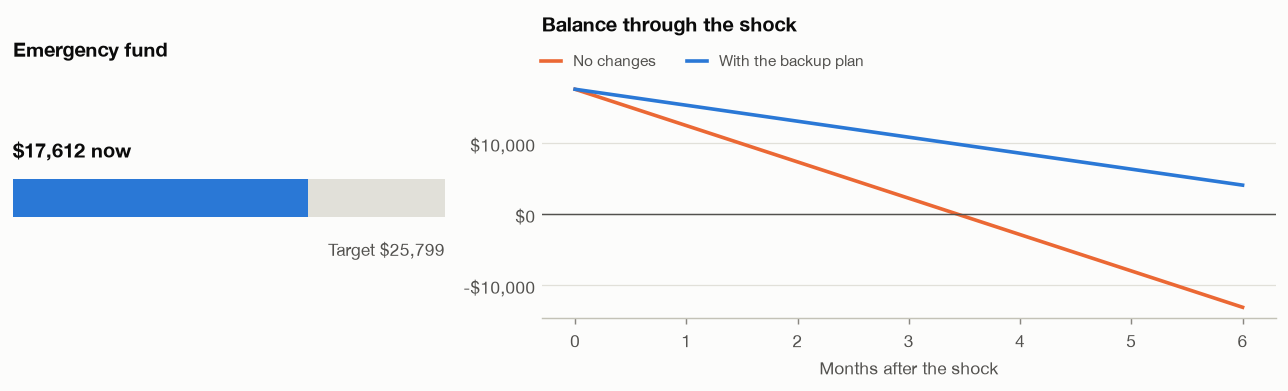

In [4]:
ACCOUNT_ID = 20111

TARGET_MONTHS = 3         # Emergency fund target, in months of spending. Try 6.

KEEP = 0.55               # Share of income kept. 0.55 is 55%. 1 means no job loss.
MONTHS = 6                # How long the lower income lasts.
BILLS_PCT = 0             # Bills increase. 15 means 15%.
REPAIR_DOLLARS = 0        # One-off cost in dollars.
REPAIR_MONTHS = 0         # One-off cost in months of spending. Adds to the dollars.
START_MONTH = None        # Calendar month, 1 to 12. Only adds a January note.

USE_EI_MAX = False        # True applies the weekly maximum.
EI_WEEKLY_MAX = 729       # Dollars a week.

bundle = show_plan(ACCOUNT_ID, target_months=TARGET_MONTHS, keep=KEEP, months=MONTHS, bills_pct=BILLS_PCT,
                   repair_dollars=REPAIR_DOLLARS, repair_months=REPAIR_MONTHS, start_month=START_MONTH,
                   use_ei_max=USE_EI_MAX, ei_weekly_max=EI_WEEKLY_MAX)

## Examples for each kind of account

### The same customer with the EI maximum on

## Plan for account 20111

### Goal plan: emergency fund

Typical spending is at or above typical money in, so nothing is left to save. Cutting $2,260 a month breaks even, and cutting $2,942 a month reaches $25,799 in 12 months.

| Measure | Value |
| :-- | --: |
| Target | $25,799 (3 months of spending) |
| Buffer now | $17,612 (2.0 months) |
| Still needed | $8,187 |
| Typical monthly surplus (I − S) | -$2,260 |
| Actual change, last 12 months (average a month) | -$748 |
| Months to goal | n/a |

**Keep the lowest balance above one loan payment ($2,330).** Its lowest point in the last 6 months was $10,418, so this is met.

### Backup plan: if the shock hits

Without changes, the money runs out in month 4 of 6. Cutting **$2,505 a month** (29% of spending) makes it last.

| Measure | Value |
| :-- | --: |
| Runway after the shock, judges' formula | 3.4 months |
| Runway after the shock, with the EI maximum *(our addition)* | 3.2 months |
| Runway after the customer's own steps | 6.8 months |
| Fixed costs | $2,330 |
| Flexible spending | $6,269 |

| Step | Action | Saves a month | One time | Runway after | Needs agreement |
| --: | :-- | --: | --: | --: | :-- |
| 1 | Bring other spending down to $3,405 a month, the level of this account's lowest quarter of months. That saves $2,864 a month. | $2,864 |  | 6.8 months |  |

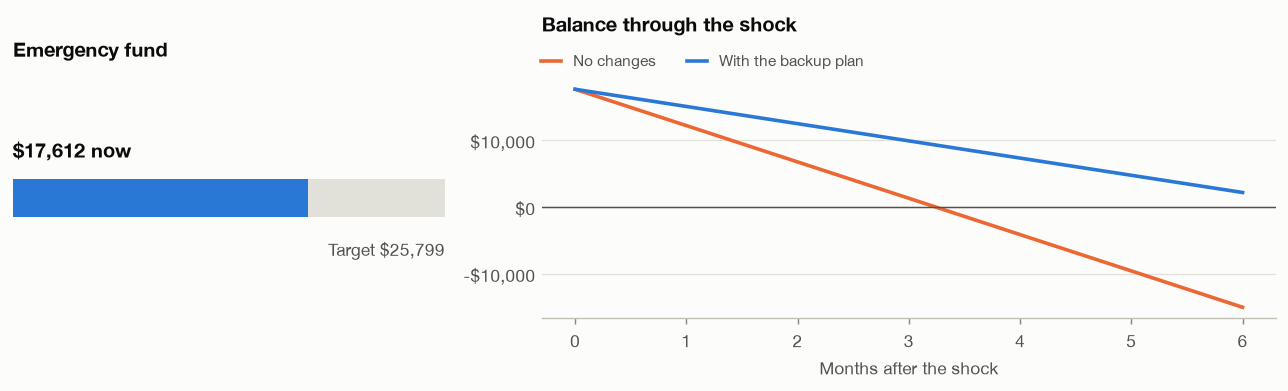

In [5]:
_ = show_plan(20111, use_ei_max=True)

### A customer with a surplus to save

## Plan for account 20133

### Goal plan: emergency fund

Saving the $3,718 monthly surplus takes the buffer from $30,198 to $61,429 (3 months of spending) in **9 months**.

| Measure | Value |
| :-- | --: |
| Target | $61,429 (3 months of spending) |
| Buffer now | $30,198 (1.5 months) |
| Still needed | $31,231 |
| Typical monthly surplus (I − S) | $3,718 |
| Actual change, last 12 months (average a month) | $809 |
| Months to goal | 9 months |

### Backup plan: if the shock hits

Without changes, the money runs out in month 5 of 6. Cutting **$2,136 a month** (10% of spending) makes it last.

| Measure | Value |
| :-- | --: |
| Runway after the shock, judges' formula | 4.2 months |
| Runway after the customer's own steps | No shortfall (120+) |
| Fixed costs | $0 |
| Flexible spending | $20,476 |

| Step | Action | Saves a month | One time | Runway after | Needs agreement |
| --: | :-- | --: | --: | --: | :-- |
| 1 | Bring other spending down to $12,406 a month, the level of this account's lowest quarter of months. That saves $8,070 a month. | $8,070 |  | No shortfall (120+) |  |

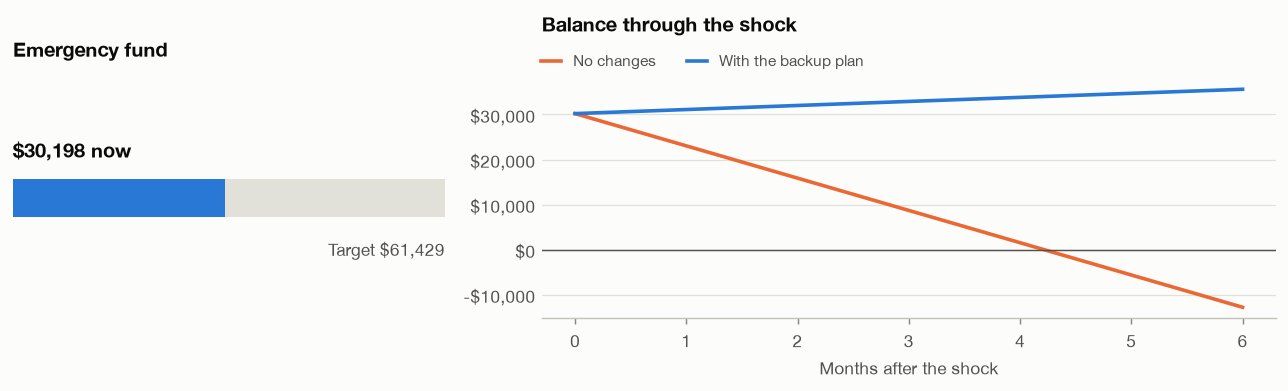

In [6]:
_ = show_plan(20133)

### A pensioner who's already there, with a 6-month target

## Plan for account 20176

### Goal plan: emergency fund

The buffer of $34,694 already covers 6 months of spending ($19,269), so no extra saving is needed.

| Measure | Value |
| :-- | --: |
| Target | $19,269 (6 months of spending) |
| Buffer now | $34,694 (10.8 months) |
| Still needed | $0 |
| Typical monthly surplus (I − S) | $1,070 |
| Actual change, last 12 months (average a month) | $640 |
| Months to goal | Reached |

### Backup plan: if the shock hits

The money lasts 6 months with no changes.

| Measure | Value |
| :-- | --: |
| Runway after the shock, judges' formula | 40.5 months |
| Fixed costs | $1,189 |
| Flexible spending | $2,023 |

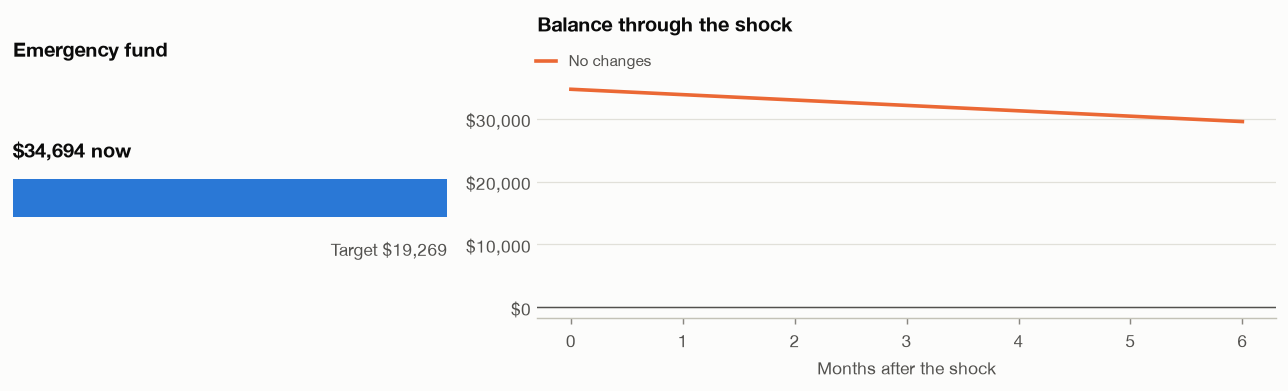

In [7]:
_ = show_plan(20176, target_months=6)

### Cuts aren't enough

## Plan for account 21755

### Goal plan: emergency fund

Typical spending is at or above typical money in, so nothing is left to save. Cutting $71 a month breaks even, and cutting $489 a month reaches $15,998 in 12 months.

| Measure | Value |
| :-- | --: |
| Target | $15,998 (3 months of spending) |
| Buffer now | $10,986 (2.1 months) |
| Still needed | $5,012 |
| Typical monthly surplus (I − S) | -$71 |
| Actual change, last 12 months (average a month) | -$227 |
| Months to goal | n/a |

**Keep the lowest balance above one loan payment ($2,245).** Its lowest point in the last 6 months was $6,103, so this is met.

### Backup plan: if the shock hits

Without changes, the money runs out in month 5 of 6. Even cutting all $155 of flexible spending doesn't make it last, so this customer also needs other help. Asking the lender is the last step below.

| Measure | Value |
| :-- | --: |
| Runway after the shock, judges' formula | 4.5 months |
| Runway after the customer's own steps | 4.8 months |
| Runway if the lender also agrees | 120.0 months |
| Fixed costs | $5,178 |
| Flexible spending | $155 |

| Step | Action | Saves a month | One time | Runway after | Needs agreement |
| --: | :-- | --: | --: | --: | :-- |
| 1 | Cut the remaining $155 a month of other spending. This leaves only fixed costs. | $155 |  | 4.8 months |  |
| 2 | Ask the lender to pause the $2,245 loan payment. This needs the lender's agreement. | $2,245 |  | 120.0 months | Yes |

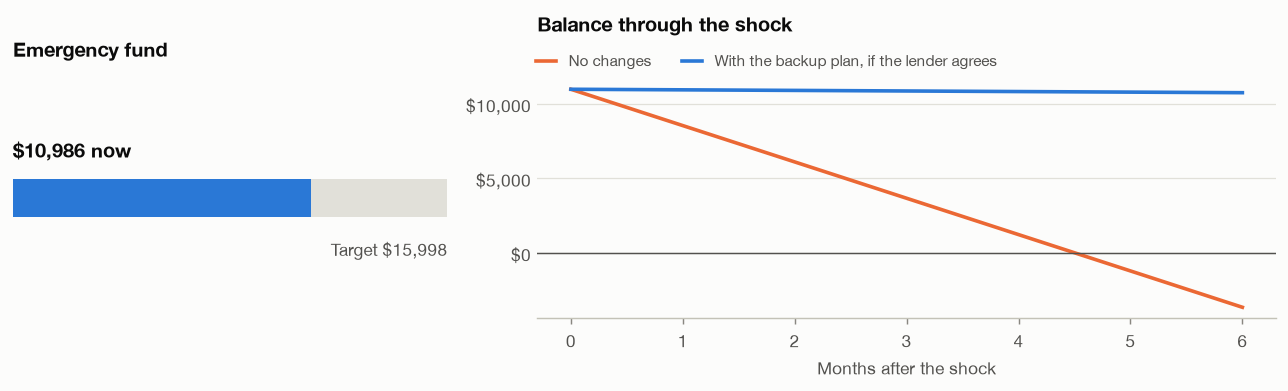

In [8]:
_ = show_plan(21755)

### No buffer

## Plan for account 32078

### Goal plan: emergency fund

Saving the $215 monthly surplus takes the buffer from -$2,513 to $8,900 (3 months of spending) in **54 months**.

| Measure | Value |
| :-- | --: |
| Target | $8,900 (3 months of spending) |
| Buffer now | -$2,513 |
| Still needed | $11,413 |
| Typical monthly surplus (I − S) | $215 |
| Actual change, last 12 months (average a month) | -$608 |
| Months to goal | 54 months |

- Typical money in is $215 above typical spending, but over the last 12 months the balance changed by -$608 a month on average. Treat the savings figure as the most this could be.

### Backup plan: if the shock hits

The buffer is already gone, so $2,513 is needed to get back to $0 before anything else. Cuts can then stop it falling further.

| Measure | Value |
| :-- | --: |
| Runway after the shock, judges' formula | 0 months |
| Runway after the customer's own steps | 0 months |
| Fixed costs | $0 |
| Flexible spending | $2,967 |

| Step | Action | Saves a month | One time | Runway after | Needs agreement |
| --: | :-- | --: | --: | --: | :-- |
| 1 | Find $2,513 to bring the balance back up to $0. Until then, runway is 0 months. |  | $2,513 | 0 months |  |
| 2 | Bring other spending down to $1,346 a month, the level of this account's lowest quarter of months. That saves $1,620 a month. | $1,620 |  | 0 months |  |

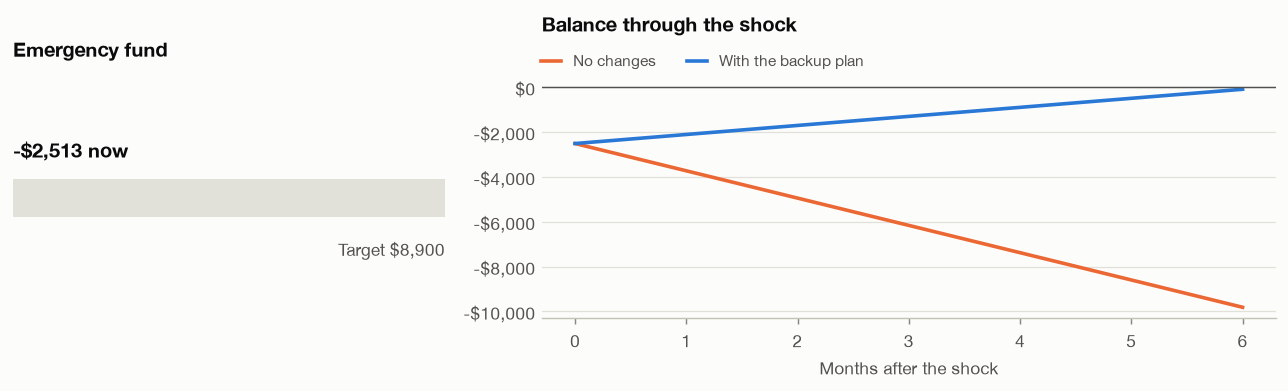

In [9]:
_ = show_plan(32078)

### Almost no activity

## Plan for account 21132

### Goal plan: emergency fund

Typical spending is $0, so a target in months of spending has no meaning for this account.

### Backup plan: if the shock hits

The money lasts 6 months with no changes.

| Measure | Value |
| :-- | --: |
| Runway after the shock, judges' formula | No shortfall (120+) |
| Fixed costs | $0 |
| Flexible spending | $0 |

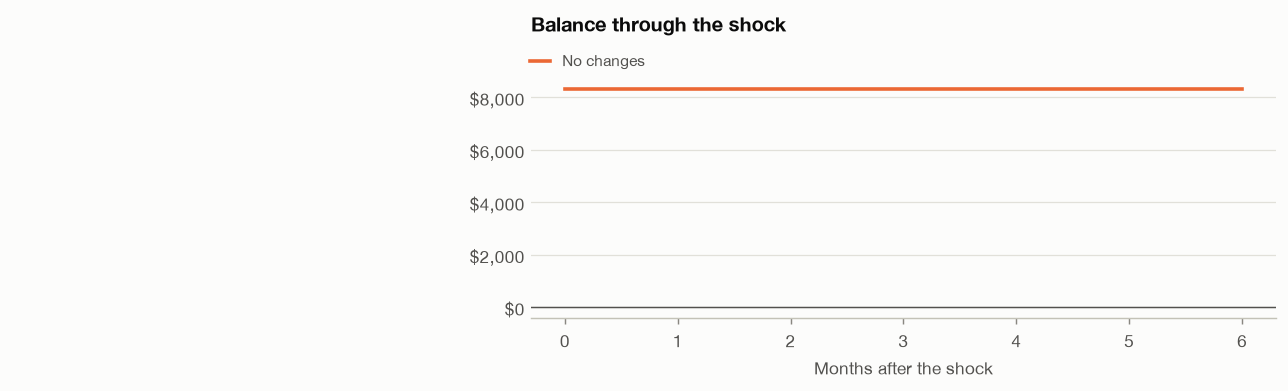

In [10]:
_ = show_plan(21132)

### A judge's mixed twist: $5,000 repair and bills up 15%, with no job loss

## Plan for account 20134

### Goal plan: emergency fund

Typical spending is at or above typical money in, so nothing is left to save. Cutting $103 a month breaks even, and cutting $734 a month reaches $24,182 in 12 months.

| Measure | Value |
| :-- | --: |
| Target | $24,182 (3 months of spending) |
| Buffer now | $16,599 (2.1 months) |
| Still needed | $7,582 |
| Typical monthly surplus (I − S) | -$103 |
| Actual change, last 12 months (average a month) | -$74 |
| Months to goal | n/a |

**Keep the lowest balance above one loan payment ($1,312).** Its lowest point in the last 6 months was $12,206, so this is met.

### Backup plan: if the shock hits

The money lasts 6 months with no changes.

| Measure | Value |
| :-- | --: |
| Runway after the shock, judges' formula | 13.2 months |
| Fixed costs | $7,253 |
| Flexible spending | $1,582 |

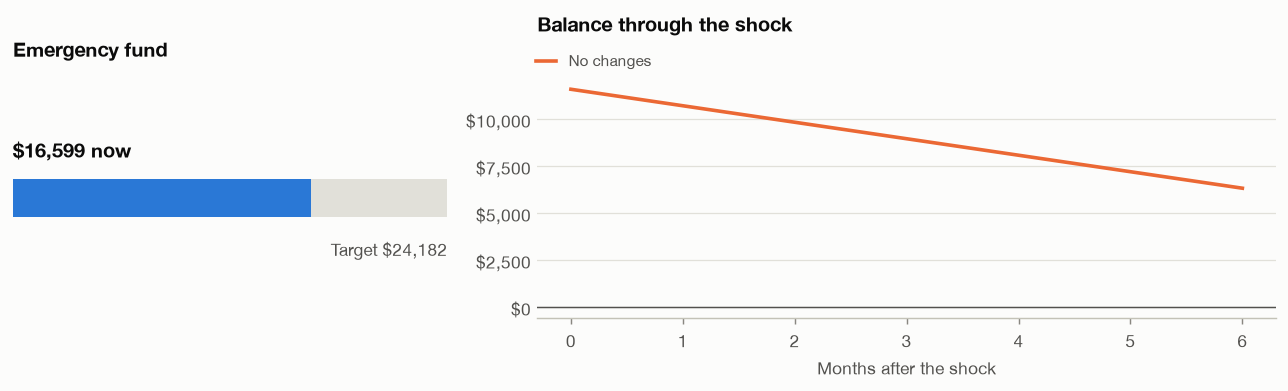

In [11]:
_ = show_plan(20134, keep=1, bills_pct=15, repair_dollars=5000)

### An ID that doesn't exist

In [12]:
_ = show_plan(12345)
_ = show_plan("abc")

**Can't make a plan.** Account 12345 isn't in the data. IDs are whole numbers, like 20111.

**Can't make a plan.** 'abc' isn't an account ID. IDs are whole numbers, like 20111.

## Across all 4,500 accounts

This runs the default plan on every account, to see what the plans can and can't do.

In [13]:
ids = sorted(pd.read_csv("data/accounts.csv").account_id)
EI_SHOCK = build_shock()

def sweep(capped=False, target_months=3):
    rows = []
    for a in ids:
        plan = make_plan(a, build_shock(weekly_max=EI_WEEKLY_MAX_2026 if capped else None), target_months=target_months)
        g, b = plan.goal, plan.backup_capped or plan.backup
        rows.append(dict(account_id=a, goal=g.state, months_to_goal=g.months_to_goal, monthly=g.monthly_amount, surplus=g.surplus,
                         still_needed=g.still_needed, actual=g.actual_change_last_12, target=g.target_amount, buffer=g.current_buffer,
                         backup=b.state, before=b.makes_it_before, after=b.makes_it_after_steps, cut=b.cut_to_last,
                         cut_share=b.cut_to_last_share_of_spending, cut_flexible=b.cut_to_last_share_of_flexible,
                         fixed_share=b.fixed_share_of_spending, steps=[s.code for s in b.steps],
                         facts=[f.code for f in plan.facts], low_met=None if plan.low_balance is None else plan.low_balance.met))
    return pd.DataFrame(rows)

flat, capped_df = sweep(), sweep(capped=True)
six = sweep(target_months=6)

goal_order = ["already_there", "on_track", "no_surplus", "no_regular_spending"]
display(pd.DataFrame({"3-month target": flat.goal.value_counts(), "6-month target": six.goal.value_counts()}).reindex(goal_order).astype(int))

,3-month target,6-month target
goal,,
already_there,2449,1222
on_track,1106,2154
no_surplus,868,1047
no_regular_spending,77,77


In [14]:
# Does the plan's surplus really reach the balance?
ot = flat[flat.goal == "on_track"].copy()
unseen = ot.actual <= 0
real_rate = ot.actual.where(ot.actual > 0)
ot["months_at_actual"] = np.ceil(ot.still_needed / real_rate)
saving = pd.Series({
    "On-track accounts": len(ot),
    "Median months to goal, from the typical surplus": ot.months_to_goal.median(),
    "Reach the goal within 12 months, from the typical surplus": (ot.months_to_goal <= 12).sum(),
    "Over 120 months to goal": (ot.months_to_goal > MANY_MONTHS).sum(),
    "Median typical surplus a month": ot.surplus.median(),
    "Median actual change a month, last 12 months": ot.actual.median(),
    "Balance didn't grow over the last 12 months": unseen.sum(),
    "Where the balance grew: median months to goal from the typical surplus": ot.months_to_goal[~unseen].median(),
    "Where the balance grew: median months to goal at the actual rate": ot.months_at_actual.median(),
    "Where the balance grew: within 12 months from the typical surplus": (ot.months_to_goal[~unseen] <= 12).sum(),
    "Where the balance grew: within 12 months at the actual rate": (ot.months_at_actual <= 12).sum(),
})
display(saving.to_frame("value"))

all_unseen = sum("surplus_not_seen_in_balance" in f for f in flat.facts)
print(f"Accounts with a surplus not seen in the balance, including those already at the target: {all_unseen:,}.")

,value
On-track accounts,"1,106.0"
"Median months to goal, from the typical surplus",12.0
"Reach the goal within 12 months, from the typical surplus",565.0
Over 120 months to goal,94.0
Median typical surplus a month,823.7
"Median actual change a month, last 12 months",237.2
Balance didn't grow over the last 12 months,444.0
Where the balance grew: median months to goal from the typical surplus,12.0
Where the balance grew: median months to goal at the actual rate,13.0
Where the balance grew: within 12 months from the typical surplus,351.0


Accounts with a surplus not seen in the balance, including those already at the target: 1,038.


,Flat 55%,With the EI maximum
backup,,
Lasts 6 months with no changes,2904,2191
Lasts with cuts,1526,2102
Cuts aren't enough,47,184
No buffer,23,23


,Flat 55%,With the EI maximum
Don't last 6 months with no changes,"1,596.0","2,309.0"
"Of those, last with the customer's own cuts","1,526.0","2,102.0"
"Of those, last with all steps, including the lender's agreement","1,548.0","2,173.0"
"Median cut, % of spending",15.7,38.5
"Median cut, % of flexible spending",21.2,49.8
Cut is over half of spending,17.0,600.0


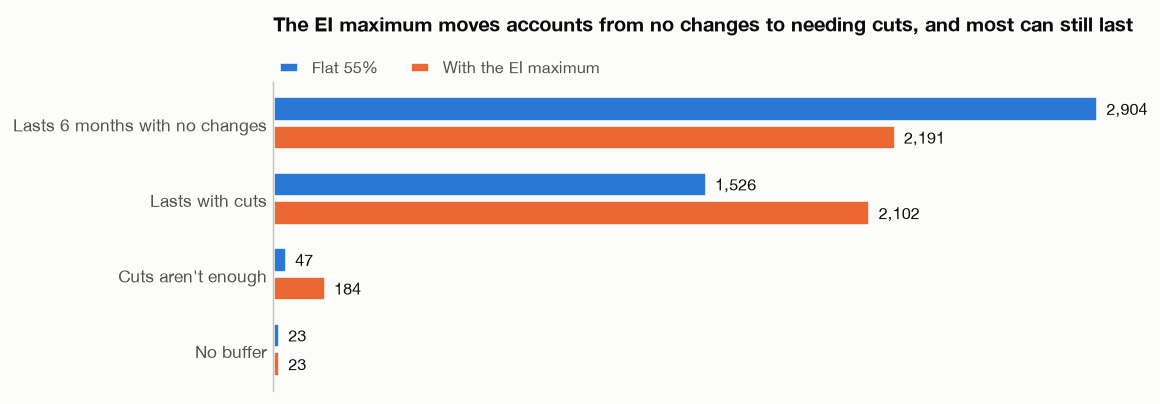

,accounts using the step
lean_months,1355
cancel_other_orders,530
all_flexible,387
ask_lender,28
cover_buffer,23


Running loans: 448. Lowest balance already above one payment: 411. Not yet: 37.
Fixed costs are a median 36% of spending.


In [15]:
# Can the backup plan rescue people, with and without the EI maximum?
state_labels = {"no_cuts_needed": "Lasts 6 months with no changes", "cuts_needed": "Lasts with cuts",
                "cuts_not_enough": "Cuts aren't enough", "no_buffer": "No buffer"}
backup_table = pd.DataFrame({"Flat 55%": flat.backup.value_counts(), "With the EI maximum": capped_df.backup.value_counts()}).reindex(state_labels).fillna(0).astype(int)
backup_table.index = backup_table.index.map(state_labels)
display(backup_table)

def rescue(df):
    short = df[df.before == False]
    needed = df[df.backup == "cuts_needed"]
    return pd.Series({
        "Don't last 6 months with no changes": len(short),
        "Of those, last with the customer's own cuts": len(needed),
        "Of those, last with all steps, including the lender's agreement": int((short.after == True).sum()),
        "Median cut, % of spending": needed.cut_share.median() * 100,
        "Median cut, % of flexible spending": needed.cut_flexible.median() * 100,
        "Cut is over half of spending": int((needed.cut_share > .5).sum()),
    })
rescue_table = pd.DataFrame({"Flat 55%": rescue(flat), "With the EI maximum": rescue(capped_df)})
display(rescue_table.round(1))

fig, ax = plt.subplots(figsize=(9, 3.2))
y = np.arange(len(backup_table))[::-1]
ax.barh(y + 0.19, backup_table["Flat 55%"], height=0.34, color=BLUE, label="Flat 55%", edgecolor=SURFACE, linewidth=2)
ax.barh(y - 0.19, backup_table["With the EI maximum"], height=0.34, color=ORANGE, label="With the EI maximum", edgecolor=SURFACE, linewidth=2)
for yy, a, b in zip(y, backup_table["Flat 55%"], backup_table["With the EI maximum"]):
    ax.text(a + 30, yy + 0.19, f"{a:,}", va="center", color=INK, fontsize=9)
    ax.text(b + 30, yy - 0.19, f"{b:,}", va="center", color=INK, fontsize=9)
ax.set_yticks(y, backup_table.index); ax.set_xticks([]); ax.tick_params(axis="y", length=0)
ax.spines["bottom"].set_visible(False); ax.spines["left"].set_color(AXIS)
ax.set_title("The EI maximum moves accounts from no changes to needing cuts, and most can still last", pad=28)
ax.legend(ncols=2, loc="lower left", bbox_to_anchor=(-0.01, 0.97), fontsize=9, handlelength=1.2)
plt.tight_layout(); plt.show()

steps_used = pd.Series([s for row in flat.steps for s in row]).value_counts()
display(steps_used.to_frame("accounts using the step"))
low = flat.low_met.dropna()
print(f"Running loans: {len(low)}. Lowest balance already above one payment: {int(low.sum())}. Not yet: {int((~low.astype(bool)).sum())}.")
print(f"Fixed costs are a median {flat.fixed_share.median():.0%} of spending.")

**Reading this:**

- **The plan is doable on paper for most people.** Most accounts that wouldn't last the period can make it with a cut well inside their flexible spending.
- **That cut isn't easy for everyone.** Flexible spending here means anything not visibly fixed. Much of it is cash withdrawals, which could include rent or other bills the data can't label.
- **A surplus on paper isn't always real.** I and S are separate medians, so I − S can be positive on an account whose balance isn't growing. The plan shows both figures, and shows a note when the two disagree.
- **Discovery gives some support.** In real income drops, most accounts' spending fell by far more than these cuts. Those are falls in deposits on cash-only accounts, not confirmed job losses, so this is supporting evidence and not proof. See [`docs/discovery.md`](docs/discovery.md).

## Checks

These recalculate the plan's main numbers from their definitions and compare them with the engine across all accounts. A separate check outside the notebook used only the raw CSVs.

In [16]:
# 1. Goal plan follows its definitions.
ok = flat[flat.goal == "on_track"]
assert (ok.monthly - ok.surplus).abs().max() < 1e-6
assert (np.ceil(ok.still_needed / ok.monthly - 1e-9) == ok.months_to_goal).all()
assert ((flat.target.dropna() >= 0)).all()
there = flat[flat.goal == "already_there"]
assert (there.buffer >= there.target).all()

# 2. Backup cut follows its definition, using the judges' gap and buffer left.
cuts = flat[flat.backup == "cuts_needed"]
diffs = []
for a, c in zip(cuts.account_id, cuts.cut):
    r = apply_shock(a, EI_SHOCK)
    diffs.append(abs((r.gap - r.buffer_left / 6) - c))
assert max(diffs) < 0.01, max(diffs)

# 3. The balance chart agrees with the plan's answer on every account with steps.
disagree = 0
for a in flat[flat.steps.str.len() > 0].account_id:
    bundle = build_plan(a)
    path = path_after_steps(bundle)
    if path is None:
        continue
    if (min(path) >= 0) != bool(bundle["backup"].makes_it_after_steps):
        disagree += 1
print(f"Chart and plan disagree on {disagree} accounts.")
assert disagree == 0

# 4. Every report builds on every account, in both modes.
for a in ids:
    plan_report(build_plan(a))
    plan_report(build_plan(a, use_ei_max=True, bills_pct=15, repair_dollars=5000))

# 5. Judges' runway never changes when the maximum is on.
for a in ids[:500]:
    assert build_plan(a, use_ei_max=True)["judges"].runway == apply_shock(a, EI_SHOCK).runway

# 6. The capped figures use min(keep x I, max) and the judges' formula.
for a in ids[:500]:
    p, c = get_profile(a), build_plan(a, use_ei_max=True)["capped"]
    assert abs(c.income_after - min(0.55 * p.I, 729 * 52 / 12)) < 0.01
assert build_plan(20111, use_ei_max=True)["capped"].runway.label == "3.2 months"

# 7. Every running loan gets a low-balance goal.
assert len(low) == 448
print("All checks passed.")

Chart and plan disagree on 0 accounts.


All checks passed.


## Check the headline numbers

In [17]:
near = lambda a, b, tol=0.5: abs(a - b) <= tol
ft, ct = backup_table["Flat 55%"], backup_table["With the EI maximum"]
assert list(ft) == [2904, 1526, 47, 23] and list(ct) == [2191, 2102, 184, 23]
assert near(rescue_table.loc["Median cut, % of spending", "Flat 55%"], 15.7, .05)
assert near(rescue_table.loc["Median cut, % of spending", "With the EI maximum"], 38.5, .05)
assert rescue_table.loc["Cut is over half of spending", "Flat 55%"] == 17
assert rescue_table.loc["Cut is over half of spending", "With the EI maximum"] == 600
assert len(ot) == 1106 and unseen.sum() == 444
assert near(ot.surplus.median(), 824, 1) and near(ot.actual.median(), 237, 1)
for df, want in ((flat, [2449, 1106, 868, 77]), (six, [1222, 2154, 1047, 77])):
    assert list(df.goal.value_counts().reindex(goal_order)) == want

print('All headline numbers match the analysis.')

All headline numbers match the analysis.
